<a href="https://colab.research.google.com/github/VIKAS-PURBIA/Task_5_Titanic_EDA/blob/main/Task_5_Titanic_EDA.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Task 5 – Exploratory Data Analysis (EDA): Titanic Dataset
**Tools:** Python, Pandas, Matplotlib, Seaborn  
**Dataset:** 891 passenger records and 12 columns.

## Objective
Explore data statistically and visually; identify patterns, trends, missing values, relationships and potential anomalies.

## 1. Import libraries and load the dataset

In [1]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid")

if not os.path.exists("titanic.csv"):
    url = "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
    df = pd.read_csv(url)
    df.to_csv("titanic.csv", index=False)
else:
    df = pd.read_csv("titanic.csv")
print("Dataset shape:", df.shape)
display(df.head())

Dataset shape: (891, 12)


,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


## 2. Dataset structure and descriptive statistics

In [2]:
df.info()
display(df.describe(include="all").T)

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
PassengerId,891.0,NaN,NaN,NaN,446.0,257.353842,1.0,223.5,446.0,668.5,891.0
Survived,891.0,NaN,NaN,NaN,0.383838,0.486592,0.0,0.0,0.0,1.0,1.0
Pclass,891.0,NaN,NaN,NaN,2.308642,0.836071,1.0,2.0,3.0,3.0,3.0
Name,891,891,"Braund, Mr. Owen Harris",1,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Sex,891,2,male,577,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Age,714.0,NaN,NaN,NaN,29.699118,14.526497,0.42,20.125,28.0,38.0,80.0
SibSp,891.0,NaN,NaN,NaN,0.523008,1.102743,0.0,0.0,0.0,1.0,8.0
Parch,891.0,NaN,NaN,NaN,0.381594,0.806057,0.0,0.0,0.0,0.0,6.0
Ticket,891,681,347082,7,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Fare,891.0,NaN,NaN,NaN,32.204208,49.693429,0.0,7.9104,14.4542,31.0,512.3292


## 3. Missing values and duplicate records

In [3]:
missing = pd.DataFrame({"Missing_Count": df.isna().sum(),
                        "Missing_Percent": (df.isna().mean()*100).round(2)})
display(missing[missing.Missing_Count > 0].sort_values("Missing_Count", ascending=False))
print("Duplicate rows:", df.duplicated().sum())

,Missing_Count,Missing_Percent
Cabin,687,77.10
Age,177,19.87
Embarked,2,0.22


Duplicate rows: 0


**Observation:** Cabin contains extensive missing data; Age also has missing values, while Embarked has only a small number. Avoid dropping all incomplete rows without considering the information lost.

## 4. Categorical value counts

In [4]:
for col in ["Survived", "Pclass", "Sex", "Embarked", "SibSp", "Parch"]:
    print("\\n", col)
    display(df[col].value_counts(dropna=False))

\n Survived


,count
Survived,
0,549
1,342


\n Pclass


,count
Pclass,
3,491
1,216
2,184


\n Sex


,count
Sex,
male,577
female,314


... (2 outputs left out)

\n SibSp


,count
SibSp,
0,608
1,209
2,28
4,18
3,16
8,7
5,5


\n Parch


,count
Parch,
0,678
1,118
2,80
5,5
3,5
4,4
6,1


## 5. Univariate numerical analysis: histograms and boxplots

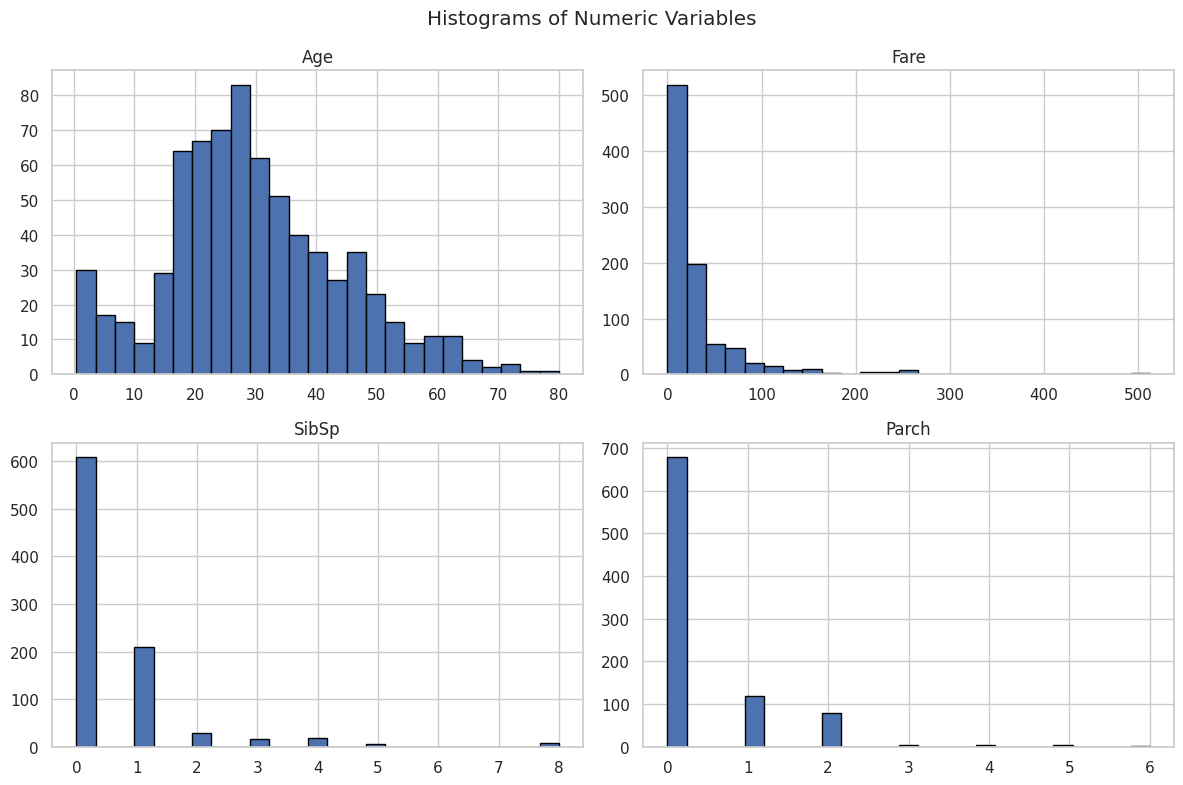

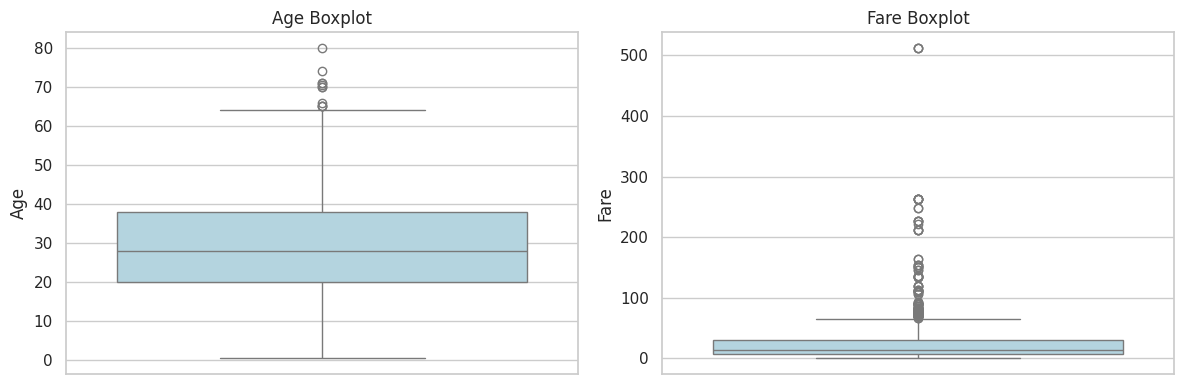

In [6]:
numeric_cols = ["Age", "Fare", "SibSp", "Parch"]
df[numeric_cols].hist(figsize=(12,8), bins=25, edgecolor="black")
plt.suptitle("Histograms of Numeric Variables")
plt.tight_layout()
plt.show()

fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.boxplot(y=df["Age"], color="lightblue", ax=axes[0]); axes[0].set_title("Age Boxplot")
sns.boxplot(y=df["Fare"], color="lightblue", ax=axes[1]); axes[1].set_title("Fare Boxplot")
plt.tight_layout(); plt.show()

**Observation:** Fare is strongly right-skewed and contains high-value observations. Age is concentrated among adults. Boxplot outliers are observations for review, not necessarily errors.

## 6. Bivariate analysis: survival by sex and passenger class

,mean,count
Sex,,
female,0.742038,314
male,0.188908,577


,mean,count
Pclass,,
1,0.629630,216
2,0.472826,184
3,0.242363,491


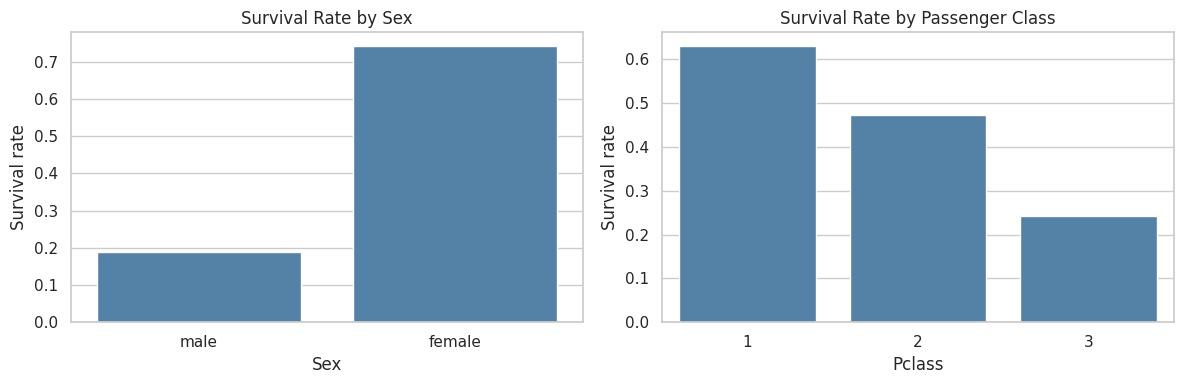

In [7]:
display(df.groupby("Sex")["Survived"].agg(["mean","count"]))
display(df.groupby("Pclass")["Survived"].agg(["mean","count"]))
fig, axes = plt.subplots(1,2,figsize=(12,4))
sns.barplot(data=df,x="Sex",y="Survived",errorbar=None,color="steelblue",ax=axes[0])
axes[0].set_title("Survival Rate by Sex"); axes[0].set_ylabel("Survival rate")
sns.barplot(data=df,x="Pclass",y="Survived",errorbar=None,color="steelblue",ax=axes[1])
axes[1].set_title("Survival Rate by Passenger Class"); axes[1].set_ylabel("Survival rate")
plt.tight_layout(); plt.show()

**Observation:** Female passengers have a substantially higher observed survival rate than male passengers. First-class passengers have a higher survival rate than second- and third-class passengers. These are associations, not causal proof.

## 7. Scatterplot and pairplot

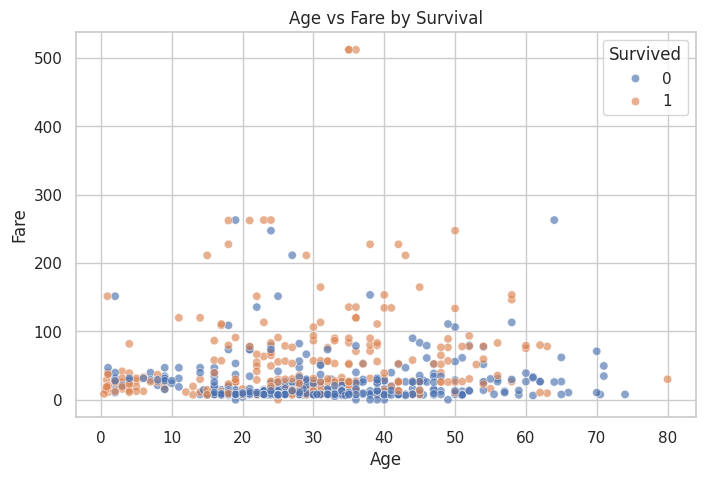

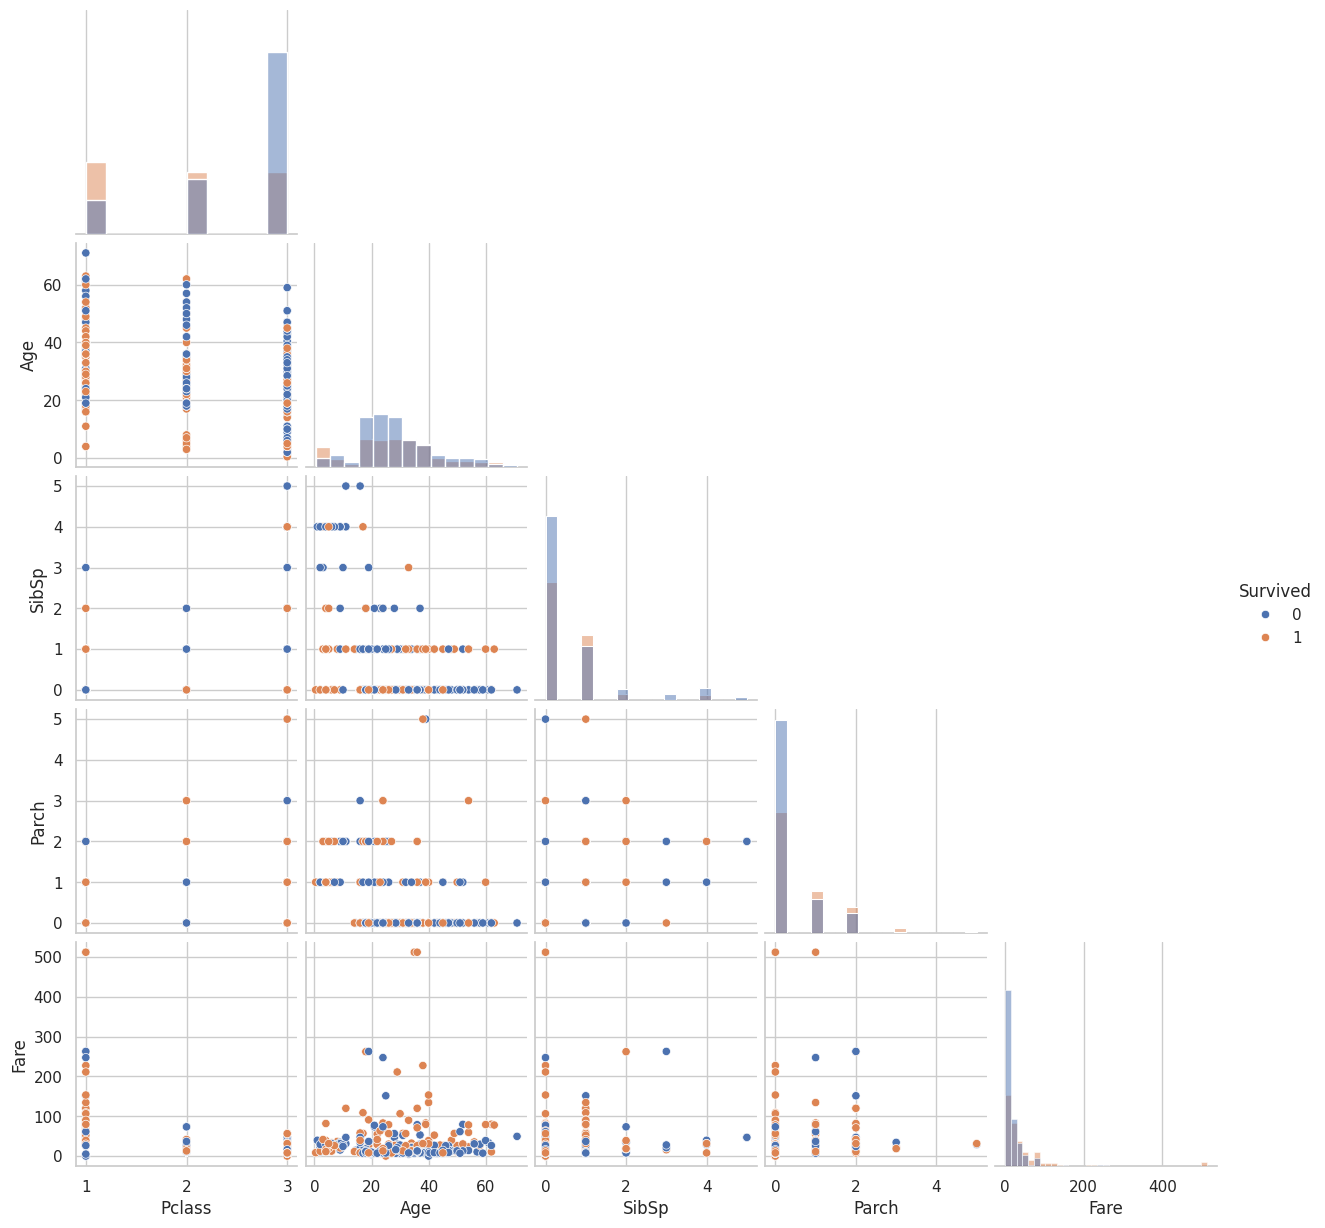

In [8]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=df,x="Age",y="Fare",hue="Survived",alpha=.65)
plt.title("Age vs Fare by Survival"); plt.show()

pair_data = df[["Survived","Pclass","Age","SibSp","Parch","Fare"]].dropna()
sns.pairplot(pair_data.sample(min(300,len(pair_data)),random_state=42),
             hue="Survived",corner=True,diag_kind="hist")
plt.show()

## 8. Correlation heatmap and multicollinearity screening

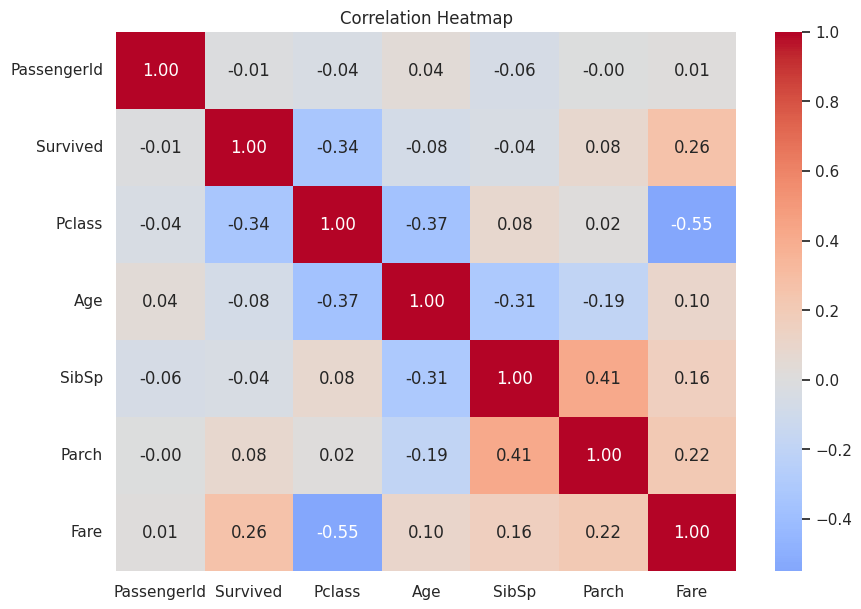

,PassengerId,Survived,Pclass,Age,SibSp,Parch,Fare
PassengerId,1.000000,-0.005007,-0.035144,0.036847,-0.057527,-0.001652,0.012658
Survived,-0.005007,1.000000,-0.338481,-0.077221,-0.035322,0.081629,0.257307
Pclass,-0.035144,-0.338481,1.000000,-0.369226,0.083081,0.018443,-0.549500
Age,0.036847,-0.077221,-0.369226,1.000000,-0.308247,-0.189119,0.096067
SibSp,-0.057527,-0.035322,0.083081,-0.308247,1.000000,0.414838,0.159651
Parch,-0.001652,0.081629,0.018443,-0.189119,0.414838,1.000000,0.216225
Fare,0.012658,0.257307,-0.549500,0.096067,0.159651,0.216225,1.000000


In [9]:
corr = df.select_dtypes(include=np.number).corr()
plt.figure(figsize=(10,7))
sns.heatmap(corr,annot=True,cmap="coolwarm",center=0,fmt=".2f")
plt.title("Correlation Heatmap"); plt.show()
display(corr)

**Observation:** The heatmap summarizes pairwise linear relationships. SibSp and Parch are related family-count variables. Correlation is only an initial screen; VIF is a more formal diagnostic for predictor multicollinearity in regression.

## 9. Skewness and robust summaries

In [10]:
for col in ["Age","Fare","SibSp","Parch"]:
    print(col, "skewness =", round(df[col].skew(),3))
display(df[["Age","Fare"]].agg(["mean","median","std","min","max"]).T)

Age skewness = 0.389
Fare skewness = 4.787
SibSp skewness = 3.695
Parch skewness = 2.749


,mean,median,std,min,max
Age,29.699118,28.0000,14.526497,0.42,80.0000
Fare,32.204208,14.4542,49.693429,0.00,512.3292


For skewed variables such as Fare, report median and IQR alongside mean and standard deviation. Consider log1p or other transformations only if appropriate for the downstream analysis.

## 10. Key findings and conclusion

In [11]:
print("Overall survival rate:", round(df.Survived.mean()*100,1), "%")
print("Survival by sex (%):")
display((df.groupby("Sex").Survived.mean()*100).round(1))
print("Survival by class (%):")
display((df.groupby("Pclass").Survived.mean()*100).round(1))
display(df.isna().sum().sort_values(ascending=False))

Overall survival rate: 38.4 %
Survival by sex (%):


,Survived
Sex,
female,74.2
male,18.9


Survival by class (%):


,Survived
Pclass,
1,63.0
2,47.3
3,24.2


,0
Cabin,687
Age,177
Embarked,2
PassengerId,0
Name,0
Pclass,0
Survived,0
Sex,0
Parch,0
SibSp,0


### Conclusion
- Survival differs substantially across sex and passenger class.
- Fare is right-skewed and contains high-value outliers.
- Cabin and Age have missing values requiring a deliberate strategy.
- Pairwise correlation does not establish causality and may miss nonlinear patterns.

**Run all cells from top to bottom.** Required packages: `pandas`, `numpy`, `matplotlib`, `seaborn`, `jupyter`.